# Motion statistics from the TimeSformer clip trajectory (target: official level)

Our best representation averages each clip's L12 token std over the whole take, so it keeps what the take looks like
and throws away how it changes. The pose oracle showed that movement (how fast, how much, how regularly) carries
signal the average misses. Pose is out of scope (video-only inference), so here the motion comes from the trajectory
of the cached per-clip TimeSformer features (1 s clips at 8 FPS; ego and best exo), no new extraction:

| block | per view | what it measures |
|---|---|---|
| `base` | 768 | L12 token std, mean over clips (the current best) |
| `tstd` | 1,536 | std over clips of L12 token std and of L12 mean token: how much the scene / body changes over the take |
| `vel` | 1,536 | mean absolute clip-to-clip change of the same two: speed of change, per dimension |
| `scalars` | 102 | for L6/L12 x CLS/mean/std: clip-to-clip cosine change (mean, std, p10/50/90, max, share of big jumps), self-similarity at 1/2/4/8/16 s, start-vs-end drift, spectrum of the top-8-PC trajectory (band powers, entropy) |

Clips are 1 s long, so anything faster than 0.5 Hz (e.g. a dance beat) is only visible through the within-clip
token spread, not through these trajectory statistics.

Protocol (level is the main target): all 2,111 official takes with video, 4 x 5-fold StratifiedGroupKFold by
participant (more takes than the 1,338 commentary ones -> tighter intervals). Blocks with > 64 dims: scenario-centered
PCA-64 fit inside the fold; scalars: scenario-centered, median-imputed, standardized. Within-scenario Spearman (ridge),
accuracy and balanced accuracy (4-class logistic). Participant bootstrap, paired against `base` ego+exo. Then the
official split (train 1,655 -> val 456, SkillFormer's test half).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from scipy.stats import spearmanr

DATA_ROOT = next(p / "data" for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "annotations").is_dir())
ANNOTATION_ROOT = DATA_ROOT / "annotations"
LEVELS = {"Novice": 1, "Early Expert": 2, "Intermediate Expert": 3, "Late Expert": 4}
meta = {}
for split_name, fname in (("train", "proficiency_demonstrator_train.json"), ("val", "proficiency_demonstrator_val.json")):
    for m in json.loads((ANNOTATION_ROOT / fname).read_text(encoding="utf-8"))["annotations"]:
        meta[m["video_paths"]["ego"].split("/")[1]] = dict(split=split_name, scenario=m["scenario_name"],
                                                           score=LEVELS[m["proficiency_score"]], participant=m["origin_participant_id"])
E = Path("embeddings")
def clip_cache(view):
    out = {}
    for name in (f"timesformer_k600_{view}8fps_clips.pt", f"timesformer_k600_{view}8fps_clips_extra.pt"):
        c = torch.load(E / name, mmap=True)["clips"]["squash"]
        out.update({t: c[t] for t in c if t in meta})
    return out
CLIPS = {"exo": clip_cache("exo"), "ego": clip_cache("ego")}
names = sorted(t for t in meta if all(t in c for c in CLIPS.values()))
split = np.array([meta[t]["split"] for t in names])
scores = np.array([meta[t]["score"] for t in names])
scenarios = np.array([meta[t]["scenario"] for t in names])
participants = np.array([meta[t]["participant"] for t in names])
SCENARIO_NAMES = np.unique(scenarios)
log_duration = np.log([len(CLIPS["exo"][t]) for t in names])
print(f"{len(names)} takes with ego and exo features ({dict(zip(*np.unique(split, return_counts=True)))}), "
      f"{len(np.unique(participants))} participants")
print(pd.crosstab(scenarios, scores))

2111 takes with ego and exo features ({np.str_('train'): np.int64(1655), np.str_('val'): np.int64(456)}), 227 participants
col_0            1    2    3    4
row_0                            
Basketball      43   89  169  239
Cooking         42   31   26    0
Dance           38  243   88  132
Music            0   14   60   98
Rock Climbing  189  201  243   89
Soccer           0    0   25   52


#### Motion features

In [2]:
from sklearn.decomposition import PCA
LAGS, N_PC = (1, 2, 4, 8, 16), 8
STAT_NAMES = {(0, 0): "L6 CLS", (0, 1): "L6 mean", (0, 2): "L6 std", (1, 0): "L12 CLS", (1, 1): "L12 mean", (1, 2): "L12 std"}
rng = np.random.default_rng(0)
train_takes = [t for t, s in zip(names, split) if s == "train"]

def unit(z):
    return z / (np.linalg.norm(z, axis=1, keepdims=True) + 1e-9)

FEATS, scalar_names = {}, None
for view, cache in CLIPS.items():
    # unsupervised PCA per (layer, stat) on a sample of TRAIN clips, for the spectral features
    pcs, big_jump = {}, {}
    for (l, s) in STAT_NAMES:
        sample = np.vstack([cache[t][:, l, s].float().numpy()[rng.choice(len(cache[t]), min(20, len(cache[t])), replace=False)]
                            for t in train_takes])
        pcs[(l, s)] = PCA(N_PC).fit(sample)
        d = np.concatenate([1 - (unit(cache[t][:, l, s].float().numpy())[1:] * unit(cache[t][:, l, s].float().numpy())[:-1]).sum(1)
                            for t in train_takes[::4]])
        big_jump[(l, s)] = np.quantile(d, 0.9)
    base, tstd, vel, scal = [], [], [], []
    for t in names:
        x = cache[t].float().numpy()  # (n, 2, 3, 768)
        n = len(x)
        std12, mean12 = x[:, 1, 2], x[:, 1, 1]
        base.append(std12.mean(0))
        tstd.append(np.concatenate([std12.std(0), mean12.std(0)]))
        vel.append(np.concatenate([np.abs(np.diff(std12, axis=0)).mean(0), np.abs(np.diff(mean12, axis=0)).mean(0)])
                   if n > 1 else np.zeros(1536))
        f = {}
        for (l, s), nm in STAT_NAMES.items():
            z = x[:, l, s]
            u = unit(z)
            d = 1 - (u[1:] * u[:-1]).sum(1) if n > 1 else np.array([np.nan])
            f[f"{nm} change mean"], f[f"{nm} change std"] = np.mean(d), np.std(d)
            for q in (10, 50, 90):
                f[f"{nm} change p{q}"] = np.percentile(d, q)
            f[f"{nm} change max"] = np.max(d)
            f[f"{nm} big-jump share"] = np.mean(d > big_jump[(l, s)])
            for lag in LAGS:
                f[f"{nm} self-sim lag {lag}s"] = (u[lag:] * u[:-lag]).sum(1).mean() if n > lag else np.nan
            q4 = max(1, n // 4)
            f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
            traj = pcs[(l, s)].transform(z)
            if n >= 8:
                p = np.abs(np.fft.rfft(traj - traj.mean(0), axis=0)) ** 2
                fr = np.fft.rfftfreq(n, 1.0)
                p, fr = p[1:], fr[1:]
                p = p / (p.sum(0, keepdims=True) + 1e-12)
                for lo, hi in ((0.0, 0.05), (0.05, 0.15), (0.15, 0.5)):
                    f[f"{nm} band {lo}-{hi}Hz"] = p[(fr > lo) & (fr <= hi)].sum(0).mean()
                f[f"{nm} spectral entropy"] = (-(p * np.log(p + 1e-12)).sum(0) / np.log(max(len(p), 2))).mean()
            else:
                for lo, hi in ((0.0, 0.05), (0.05, 0.15), (0.15, 0.5)):
                    f[f"{nm} band {lo}-{hi}Hz"] = np.nan
                f[f"{nm} spectral entropy"] = np.nan
        if scalar_names is None:
            scalar_names = list(f)
        scal.append([f[k] for k in scalar_names])
    FEATS[view] = {"base": np.stack(base), "tstd": np.stack(tstd), "vel": np.stack(vel), "scalars": np.array(scal, np.float64)}
    print(view, {k: v.shape for k, v in FEATS[view].items()}, "scalar NaN share", np.isnan(FEATS[view]["scalars"]).mean().round(3), flush=True)
del CLIPS

C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a singl

C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a singl

C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a singl

C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a singl

C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a singl

C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a singl

... (149 outputs left out)

C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a singl

C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a singl

ego {'base': (2111, 768), 'tstd': (2111, 1536), 'vel': (2111, 1536), 'scalars': (2111, 102)} scalar NaN share 0.013


C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  f[f"{nm} drift"] = 1 - float(unit(z[:q4].mean(0, keepdims=True)) @ unit(z[-q4:].mean(0, keepdims=True)).T)
C:\Users\darkn\AppData\Local\Temp\ipykernel_40008\2792069220.py:43: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a singl

#### What do the motion scalars track? (univariate, within scenario, all takes)

In [3]:
def within_scenario(x, scen):
    x = np.asarray(x, float).copy()
    for s in np.unique(scen):
        m = scen == s
        x[m] -= np.nanmean(x[m])
    return x
level_c = within_scenario(scores, scenarios)
dur_c = within_scenario(log_duration, scenarios)
rows = []
for view in ("exo", "ego"):
    S = FEATS[view]["scalars"]
    for j, nm in enumerate(scalar_names):
        ok = np.isfinite(S[:, j])
        xc = within_scenario(S[ok, j], scenarios[ok])
        rows.append({"view": view, "feature": nm, "rho level": spearmanr(xc, level_c[ok])[0],
                     "rho duration": spearmanr(xc, dur_c[ok])[0]})
U = pd.DataFrame(rows)
print(U.reindex(U["rho level"].abs().sort_values(ascending=False).index).head(15).round(3).to_string(index=False))

view                   feature  rho level  rho duration
 ego        L12 std change p50      0.153        -0.058
 ego   L12 std self-sim lag 1s     -0.152         0.066
 ego       L12 std change mean      0.152        -0.066
 ego    L12 std big-jump share      0.145        -0.022
 ego  L12 std self-sim lag 16s     -0.141         0.056
 ego  L12 std band 0.05-0.15Hz     -0.127        -0.313
 ego   L6 std band 0.05-0.15Hz     -0.122        -0.241
 ego   L12 std self-sim lag 8s     -0.120         0.018
 ego        L12 std change p90      0.113        -0.013
 exo        L6 std change mean     -0.112        -0.109
 exo    L6 std self-sim lag 1s      0.112         0.109
 ego L12 mean band 0.05-0.15Hz     -0.112        -0.319
 ego  L12 std spectral entropy     -0.111         0.126
 ego       L12 mean change p50      0.111        -0.046
 ego  L12 CLS band 0.05-0.15Hz     -0.110        -0.322


#### Cross-validation over all official takes

In [4]:
from sklearn.linear_model import LogisticRegressionCV, RidgeCV
from sklearn.metrics import balanced_accuracy_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler

N_REPEATS, N_FOLDS, PCA_DIMS = 4, 5, 64

def block_matrix(key, fit):
    if key == "duration":
        d = log_duration[:, None].copy()
        for s in SCENARIO_NAMES:
            m = scenarios == s
            d[m] -= d[np.intersect1d(fit, np.flatnonzero(m))].mean()
        return np.hstack([d * (scenarios == s)[:, None] for s in SCENARIO_NAMES])
    view, kind = key.split(":")
    X = FEATS[view][kind].astype(np.float64).copy()
    fitmask = np.zeros(len(X), bool); fitmask[fit] = True
    if kind == "scalars":
        med = np.nanmedian(X[fitmask], 0)
        X = np.where(np.isfinite(X), X, med)
    for s in SCENARIO_NAMES:
        m = scenarios == s
        X[m] -= X[fitmask & m].mean(0)
    if X.shape[1] > PCA_DIMS:
        return PCA(PCA_DIMS, svd_solver="full").fit(X[fit]).transform(X)
    X = StandardScaler().fit(X[fit]).transform(X)
    return np.clip(X, -6, 6)

def views(kinds, vs=("ego", "exo")):
    return [f"{v}:{k}" for v in vs for k in kinds]
METHODS = {
    "scenario only": [],
    "duration only": ["duration"],
    "base (current best)": views(["base"]),
    "base + duration": views(["base"]) + ["duration"],
    "base + tstd": views(["base", "tstd"]),
    "base + vel": views(["base", "vel"]),
    "base + scalars": views(["base", "scalars"]),
    "base + tstd + vel + scalars": views(["base", "tstd", "vel", "scalars"]),
    "motion only (tstd + vel + scalars)": views(["tstd", "vel", "scalars"]),
    "exo base": views(["base"], ("exo",)),
    "exo base + all motion": views(["base", "tstd", "vel", "scalars"], ("exo",)),
    "ego base": views(["base"], ("ego",)),
    "ego base + all motion": views(["base", "tstd", "vel", "scalars"], ("ego",)),
}

def fit_predict(blocks, fit, held, cache):
    onehot = OneHotEncoder(handle_unknown="ignore").fit(scenarios[fit][:, None]).transform(scenarios[:, None]).toarray()
    parts = [onehot]
    for b in blocks:
        if b not in cache:
            cache[b] = block_matrix(b, fit)
        parts.append(cache[b])
    X = np.hstack(parts)
    X = StandardScaler().fit(X[fit]).transform(X)
    ridge = RidgeCV(alphas=np.logspace(-2, 6, 17)).fit(X[fit], scores[fit])
    logit = LogisticRegressionCV(Cs=np.logspace(-4, 2, 7), cv=5, max_iter=5000, n_jobs=-1).fit(X[fit], scores[fit])
    return ridge.predict(X[held]), logit.predict(X[held])

cont = {m: np.full((N_REPEATS, len(names)), np.nan) for m in METHODS}
label = {m: np.zeros((N_REPEATS, len(names)), int) for m in METHODS}
fold_of = np.zeros((N_REPEATS, len(names)), int)
for repeat in range(N_REPEATS):
    folds = StratifiedGroupKFold(N_FOLDS, shuffle=True, random_state=repeat).split(np.zeros(len(names)), scores, participants)
    for fold, (fit, held) in enumerate(folds):
        fold_of[repeat, held] = fold
        cache = {}
        for m, blocks in METHODS.items():
            c, l = fit_predict(blocks, fit, held, cache)
            cont[m][repeat, held], label[m][repeat, held] = c, l
    print(f"repeat {repeat + 1} done", flush=True)

repeat 1 done


repeat 2 done


repeat 3 done


repeat 4 done


In [5]:
N_BOOTSTRAP = 1000
def centered(c):
    out = c.copy()
    for r in range(N_REPEATS):
        for f in range(N_FOLDS):
            for s in SCENARIO_NAMES:
                g = (fold_of[r] == f) & (scenarios == s)
                out[r, g] -= c[r, g].mean()
    return out.mean(0)
P = {m: centered(v) for m, v in cont.items()}
HIT = {m: (label[m] == scores).mean(0) for m in METHODS}  # accuracy per take, averaged over repeats
upart = np.unique(participants)
rows_of = {p: np.flatnonzero(participants == p) for p in upart}
boot = np.random.default_rng(0)
res = [np.concatenate([rows_of[p] for p in boot.choice(upart, len(upart))]) for _ in range(N_BOOTSTRAP)]
def sp(a, b):
    return spearmanr(a, b)[0] if np.std(a) > 1e-12 else 0.0
R = {m: {"rho": (sp(P[m], level_c), np.array([sp(P[m][r], level_c[r]) for r in res])),
         "acc": (HIT[m].mean(), np.array([HIT[m][r].mean() for r in res])),
         "bal": np.mean([balanced_accuracy_score(scores, label[m][r]) for r in range(N_REPEATS)])} for m in METHODS}
def ci(m, k):
    v, b = R[m][k]
    return f"{v:.3f} [{np.quantile(b, .025):.3f}, {np.quantile(b, .975):.3f}]"
print(f"{'method':<38}{'Spearman (within scenario)':>28}{'accuracy':>24}{'balanced':>10}")
for m in METHODS:
    print(f"{m:<38}{ci(m, 'rho'):>28}{ci(m, 'acc'):>24}{R[m]['bal']:>10.3f}")
def diff(a, b, k):
    d = R[a][k][1] - R[b][k][1]
    lo, hi = np.quantile(d, [0.025, 0.975])
    return f"{R[a][k][0] - R[b][k][0]:+.3f} [{lo:+.3f}, {hi:+.3f}]" + (" *" if lo > 0 or hi < 0 else "  ")
print("\npaired differences vs base (* = 95% participant-bootstrap CI excludes 0)")
for a, b in [("base + duration", "base (current best)"), ("base + tstd", "base (current best)"), ("base + vel", "base (current best)"),
             ("base + scalars", "base (current best)"), ("base + tstd + vel + scalars", "base (current best)"),
             ("motion only (tstd + vel + scalars)", "base (current best)"), ("exo base + all motion", "exo base"),
             ("ego base + all motion", "ego base")]:
    print(f"  {a + ' - ' + b:<62} Spearman {diff(a, b, 'rho')}   accuracy {diff(a, b, 'acc')}")
print("\nper scenario, within-scenario Spearman (n takes)")
show = ["duration only", "base (current best)", "base + tstd + vel + scalars", "motion only (tstd + vel + scalars)"]
tab = pd.DataFrame({m: {s: sp(P[m][scenarios == s], level_c[scenarios == s]) for s in SCENARIO_NAMES} for m in show})
tab.insert(0, "n", [int((scenarios == s).sum()) for s in SCENARIO_NAMES])
print(tab.round(3).to_string())

method                                  Spearman (within scenario)                accuracy  balanced
scenario only                                 0.000 [0.000, 0.000]    0.366 [0.307, 0.433]     0.330
duration only                                 0.159 [0.081, 0.243]    0.361 [0.308, 0.425]     0.323
base (current best)                           0.452 [0.334, 0.559]    0.386 [0.339, 0.435]     0.367
base + duration                               0.459 [0.343, 0.566]    0.388 [0.342, 0.436]     0.368
base + tstd                                   0.443 [0.331, 0.547]    0.377 [0.337, 0.418]     0.358
base + vel                                    0.449 [0.332, 0.552]    0.378 [0.337, 0.420]     0.362
base + scalars                                0.431 [0.316, 0.538]    0.392 [0.351, 0.434]     0.369
base + tstd + vel + scalars                   0.439 [0.328, 0.542]    0.378 [0.339, 0.420]     0.360
motion only (tstd + vel + scalars)            0.374 [0.278, 0.463]    0.347 [0.313, 0.387] 

#### Official split (train 1,655 -> val)

In [6]:
with open("models/SkillFormer/annotation_test.jsonl", encoding="utf-8") as f:
    sf_test = {json.loads(line)["video_paths"][0].split("/")[1] for line in f}
o_fit, o_val = np.flatnonzero(split == "train"), np.flatnonzero(split == "val")
EVALS = {"full val": o_val, "SkillFormer test half": o_val[np.isin(np.array(names)[o_val], list(sf_test))]}
OFFICIAL = ["scenario only", "duration only", "base (current best)", "base + tstd", "base + vel", "base + scalars",
            "base + tstd + vel + scalars", "motion only (tstd + vel + scalars)"]
cache, o_out = {}, {}
for m in OFFICIAL:
    c, l = fit_predict(METHODS[m], o_fit, np.arange(len(names)), cache)
    o_out[m] = (c, l)
ob = np.random.default_rng(0)
for ev, idx in EVALS.items():
    y, sc, pt = scores[idx], scenarios[idx], participants[idx]
    lc = within_scenario(y, sc)
    up = np.unique(pt); ro = {p: np.flatnonzero(pt == p) for p in up}
    rs = [np.concatenate([ro[p] for p in ob.choice(up, len(up))]) for _ in range(N_BOOTSTRAP)]
    print(f"\n-- {ev} (n={len(idx)}, {len(up)} participants)")
    print(f"{'method':<38}{'accuracy':>24}{'balanced':>10}{'Spearman (within scenario)':>30}")
    B = {}
    for m in OFFICIAL:
        c, l = o_out[m][0][idx], o_out[m][1][idx]
        c = within_scenario(c, sc)
        hit = (l == y).astype(float)
        ab, rb = np.array([hit[r].mean() for r in rs]), np.array([sp(c[r], lc[r]) for r in rs])
        B[m] = (hit.mean(), ab, sp(c, lc), rb)
        print(f"{m:<38}{hit.mean():>8.3f} [{np.quantile(ab, .025):.3f}, {np.quantile(ab, .975):.3f}]{balanced_accuracy_score(y, l):>10.3f}"
              f"{sp(c, lc):>+14.3f} [{np.quantile(rb, .025):+.3f}, {np.quantile(rb, .975):+.3f}]")
    for a in OFFICIAL[3:]:
        da, dr = B[a][1] - B["base (current best)"][1], B[a][3] - B["base (current best)"][3]
        print(f"  {a + ' - base':<44} accuracy {B[a][0] - B['base (current best)'][0]:+.3f} [{np.quantile(da, .025):+.3f}, {np.quantile(da, .975):+.3f}]"
              f"   Spearman {B[a][2] - B['base (current best)'][2]:+.3f} [{np.quantile(dr, .025):+.3f}, {np.quantile(dr, .975):+.3f}]")


-- full val (n=456, 56 participants)
method                                                accuracy  balanced    Spearman (within scenario)
scenario only                            0.314 [0.182, 0.471]     0.332        +0.000 [+0.000, +0.000]
duration only                            0.452 [0.302, 0.611]     0.373        +0.162 [-0.011, +0.351]


base (current best)                      0.452 [0.322, 0.591]     0.412        +0.369 [+0.114, +0.594]
base + tstd                              0.375 [0.260, 0.506]     0.366        +0.374 [+0.143, +0.574]


base + vel                               0.441 [0.322, 0.561]     0.396        +0.352 [+0.105, +0.569]
base + scalars                           0.474 [0.369, 0.589]     0.452        +0.367 [+0.128, +0.574]


base + tstd + vel + scalars              0.434 [0.324, 0.553]     0.419        +0.359 [+0.133, +0.554]
motion only (tstd + vel + scalars)       0.408 [0.302, 0.534]     0.339        +0.263 [+0.067, +0.443]
  base + tstd - base                           accuracy -0.077 [-0.157, -0.018]   Spearman +0.005 [-0.050, +0.055]
  base + vel - base                            accuracy -0.011 [-0.062, +0.038]   Spearman -0.017 [-0.071, +0.038]
  base + scalars - base                        accuracy +0.022 [-0.041, +0.078]   Spearman -0.002 [-0.052, +0.051]
  base + tstd + vel + scalars - base           accuracy -0.018 [-0.086, +0.039]   Spearman -0.010 [-0.096, +0.075]
  motion only (tstd + vel + scalars) - base    accuracy -0.044 [-0.190, +0.093]   Spearman -0.105 [-0.237, +0.027]

-- SkillFormer test half (n=229, 53 participants)
method                                                accuracy  balanced    Spearman (within scenario)
scenario only                            0.319 [0.180, 0.475]    

duration only                            0.459 [0.296, 0.620]     0.386        +0.084 [-0.116, +0.306]
base (current best)                      0.437 [0.300, 0.592]     0.379        +0.372 [+0.079, +0.629]


base + tstd                              0.349 [0.242, 0.476]     0.324        +0.376 [+0.129, +0.602]
base + vel                               0.419 [0.310, 0.545]     0.351        +0.335 [+0.093, +0.570]


base + scalars                           0.489 [0.384, 0.609]     0.462        +0.365 [+0.091, +0.605]
base + tstd + vel + scalars              0.432 [0.319, 0.558]     0.404        +0.341 [+0.115, +0.554]


motion only (tstd + vel + scalars)       0.371 [0.264, 0.508]     0.310        +0.249 [+0.055, +0.454]
  base + tstd - base                           accuracy -0.087 [-0.198, -0.005]   Spearman +0.004 [-0.059, +0.067]
  base + vel - base                            accuracy -0.017 [-0.084, +0.047]   Spearman -0.037 [-0.115, +0.045]
  base + scalars - base                        accuracy +0.052 [-0.033, +0.123]   Spearman -0.007 [-0.080, +0.061]
  base + tstd + vel + scalars - base           accuracy -0.004 [-0.080, +0.061]   Spearman -0.031 [-0.156, +0.097]
  motion only (tstd + vel + scalars) - base    accuracy -0.066 [-0.226, +0.093]   Spearman -0.123 [-0.296, +0.058]


#### Figure

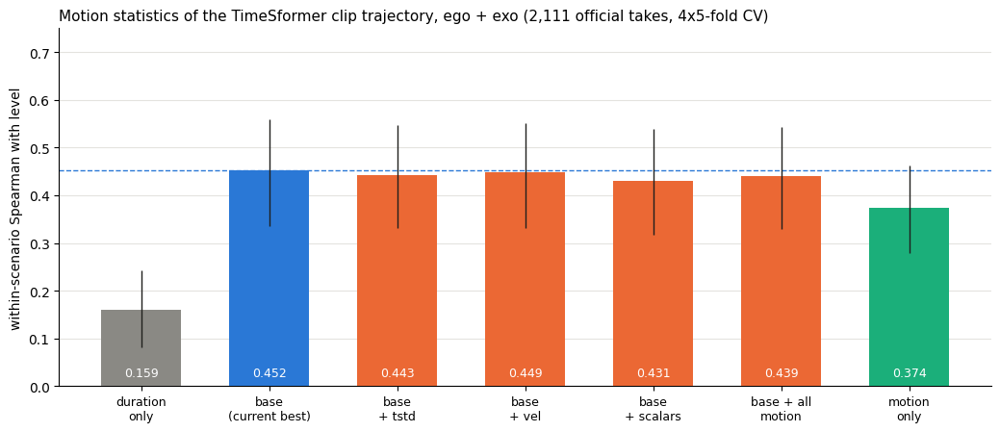

In [7]:
import matplotlib.pyplot as plt
show = ["duration only", "base (current best)", "base + tstd", "base + vel", "base + scalars", "base + tstd + vel + scalars",
        "motion only (tstd + vel + scalars)"]
labels = ["duration\nonly", "base\n(current best)", "base\n+ tstd", "base\n+ vel", "base\n+ scalars", "base + all\nmotion", "motion\nonly"]
fig, ax = plt.subplots(figsize=(10.5, 4.6))
vals = np.array([R[m]["rho"][0] for m in show])
lo = np.array([np.quantile(R[m]["rho"][1], .025) for m in show]); hi = np.array([np.quantile(R[m]["rho"][1], .975) for m in show])
colors = ["#8a8984", "#2a78d6", *["#eb6834"] * 4, "#1baf7a"]
ax.bar(range(len(show)), vals, 0.62, color=colors, zorder=3)
ax.errorbar(range(len(show)), vals, yerr=[vals - lo, hi - vals], fmt="none", ecolor="#1f1f1d", elinewidth=1, zorder=4)
for i, v in enumerate(vals):
    ax.text(i, 0.015, f"{v:.3f}", ha="center", va="bottom", fontsize=9, color="white", zorder=5)
ax.axhline(R["base (current best)"]["rho"][0], color="#2a78d6", lw=1, ls="--", zorder=2)
ax.set_xticks(range(len(show)), labels, fontsize=9)
ax.set_ylabel("within-scenario Spearman with level")
ax.set_ylim(0, max(0.75, hi.max() + 0.05))
ax.grid(axis="y", color="#e4e3df", zorder=0)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.set_title(f"Motion statistics of the TimeSformer clip trajectory, ego + exo ({len(names):,} official takes, 4x5-fold CV)",
             loc="left", fontsize=11)
fig.tight_layout()
fig.savefig("figures/motion_stats.png", dpi=150)
plt.show()